# 05. Giải thích mô hình: nó học được điều gì?

**Mục tiêu học:** mở "hộp đen". Biết ba công cụ: độ quan trọng thuộc tính (impurity và permutation), đồ thị phụ thuộc từng phần (PDP/ICE), phân tích "nếu... thì" (what-if); và biết giới hạn của chúng.

**Nội dung**
1. Huấn luyện mô hình để giải thích
2. Độ quan trọng theo impurity (cách của cây)
3. Permutation importance (đáng tin hơn)
4. Partial dependence và ICE
5. Phân tích what-if cho một chiếc xe cụ thể
6. Những điều không nên suy diễn

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score

from used_car_price.config import FEATURES, CATEGORICAL, NUMERIC, TARGET, RANDOM_STATE, RAW_PATH, TEST_SIZE
from used_car_price.data import load_data
from used_car_price.features import build_preprocessor
from used_car_price.train import log_target, candidates
from used_car_price.metrics import evaluate

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (7, 4.2)

df = load_data(); X, y = df[FEATURES], df[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

## 1. Huấn luyện mô hình để giải thích

In [2]:
model = log_target(Pipeline([("prep", build_preprocessor(False)), ("model", RandomForestRegressor(300, min_samples_leaf=2, random_state=0, n_jobs=-1))])).fit(X_tr, y_tr)
print({k: round(v, 3) for k, v in evaluate(y_te, model.predict(X_te)).items()})

{'MAPE': 0.125, 'sai_so_%_trung_vi': 0.073, 'MAE': 147.52, 'RMSE': 380.007, 'R2': 0.907}


## 2. Độ quan trọng theo impurity

Cây đo mỗi đặc trưng đã giảm độ tạp bao nhiêu khi được dùng để chia. Sau one-hot, một thuộc tính gốc (vd. `brand`) trở thành nhiều cột, nên ta **cộng dồn theo thuộc tính gốc**.

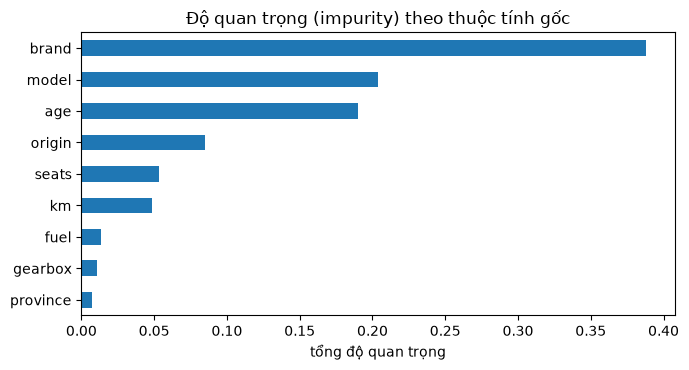

{'brand': 0.388, 'model': 0.204, 'age': 0.19, 'origin': 0.085, 'seats': 0.053, 'km': 0.048, 'fuel': 0.014, 'gearbox': 0.011, 'province': 0.007}


In [3]:
prep_f = model.regressor_[0]; rf = model.regressor_[-1]
names = prep_f.get_feature_names_out()
imp = pd.Series(rf.feature_importances_, index=names)
grouped = imp.groupby(lambda s: s.split("__")[1].split("_")[0]).sum().sort_values()
grouped.plot.barh(figsize=(7, 3.8), title="Độ quan trọng (impurity) theo thuộc tính gốc"); plt.xlabel("tổng độ quan trọng"); plt.tight_layout(); plt.show()
print(grouped.sort_values(ascending=False).round(3).to_dict())

**Cảnh báo:** độ quan trọng theo impurity **thiên lệch** về các thuộc tính có nhiều giá trị khác nhau (liên tục, hoặc one-hot nhiều cột như `model`) và được tính trên dữ liệu train. Hãy kiểm chứng bằng phương pháp dưới.

## 3. Permutation importance

Xáo trộn ngẫu nhiên **một cột** của tập test rồi xem sai số tăng bao nhiêu. Cột nào làm sai số tăng nhiều thì mô hình dựa vào nó. Áp dụng trực tiếp lên pipeline với **cột gốc**, và dùng tập test nên phản ánh khả năng tổng quát.

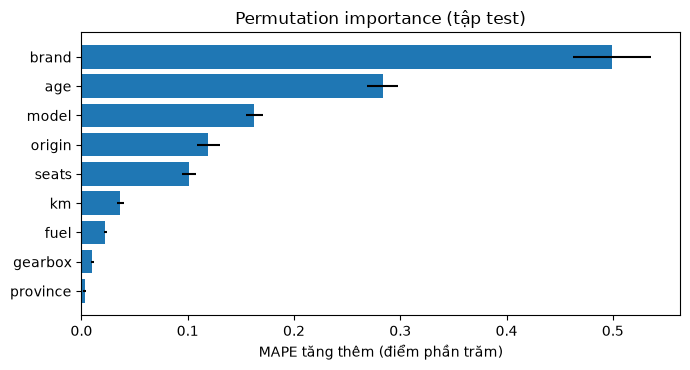

,tăng MAPE khi xáo trộn,độ lệch chuẩn
brand,49.94,3.70
age,28.36,1.45
model,16.26,0.78
origin,11.93,1.10
seats,10.12,0.69
km,3.65,0.34
fuel,2.26,0.17
gearbox,1.02,0.14
province,0.30,0.11


In [4]:
pi = permutation_importance(model, X_te, y_te, scoring="neg_mean_absolute_percentage_error", n_repeats=10, random_state=0, n_jobs=-1)
perm = pd.DataFrame({"tăng MAPE khi xáo trộn": pi.importances_mean, "độ lệch chuẩn": pi.importances_std}, index=X_te.columns).sort_values("tăng MAPE khi xáo trộn")
fig, ax = plt.subplots(figsize=(7, 3.8)); ax.barh(perm.index, perm["tăng MAPE khi xáo trộn"], xerr=perm["độ lệch chuẩn"])
ax.set_xlabel("MAPE tăng thêm (điểm phần trăm)"); ax.set_title("Permutation importance (tập test)"); plt.tight_layout(); plt.show()
display((perm.sort_values("tăng MAPE khi xáo trộn", ascending=False) * 100).round(2))

**So sánh với phần 2:** thứ hạng có thể khác (đặc biệt `model`, `age`, `km`). Khi hai đặc trưng tương quan (`age` và `km`), xáo trộn một cái làm mô hình vẫn dựa được vào cái kia, nên **mỗi cái đều bị đánh giá thấp**. Thử xáo trộn cả hai cùng lúc để kiểm chứng:

In [5]:
rng = np.random.default_rng(0)
base = evaluate(y_te, model.predict(X_te))["MAPE"]
def shuffled_mape(cols, reps=10):
    out = []
    for _ in range(reps):
        Xs = X_te.copy(); perm_idx = rng.permutation(len(Xs))
        for c in cols: Xs[c] = Xs[c].values[perm_idx]          # xáo trộn cùng thứ tự để giữ quan hệ giữa các cột trong nhóm
        out.append(evaluate(y_te, model.predict(Xs))["MAPE"] - base)
    return np.mean(out)
for cols in [["age"], ["km"], ["age", "km"]]:
    print(f"Xáo trộn {cols}: MAPE tăng {shuffled_mape(cols)*100:.2f} điểm %")

Xáo trộn ['age']: MAPE tăng 28.39 điểm %


Xáo trộn ['km']: MAPE tăng 3.76 điểm %


Xáo trộn ['age', 'km']: MAPE tăng 34.98 điểm %


## 4. Partial dependence (PDP) và ICE

**PDP** cho thấy giá dự đoán trung bình thay đổi thế nào khi đổi **một** thuộc tính, các thuộc tính khác giữ nguyên giá trị thực của từng xe rồi lấy trung bình. **ICE** vẽ đường riêng cho từng xe, cho thấy tương tác (các đường không song song).

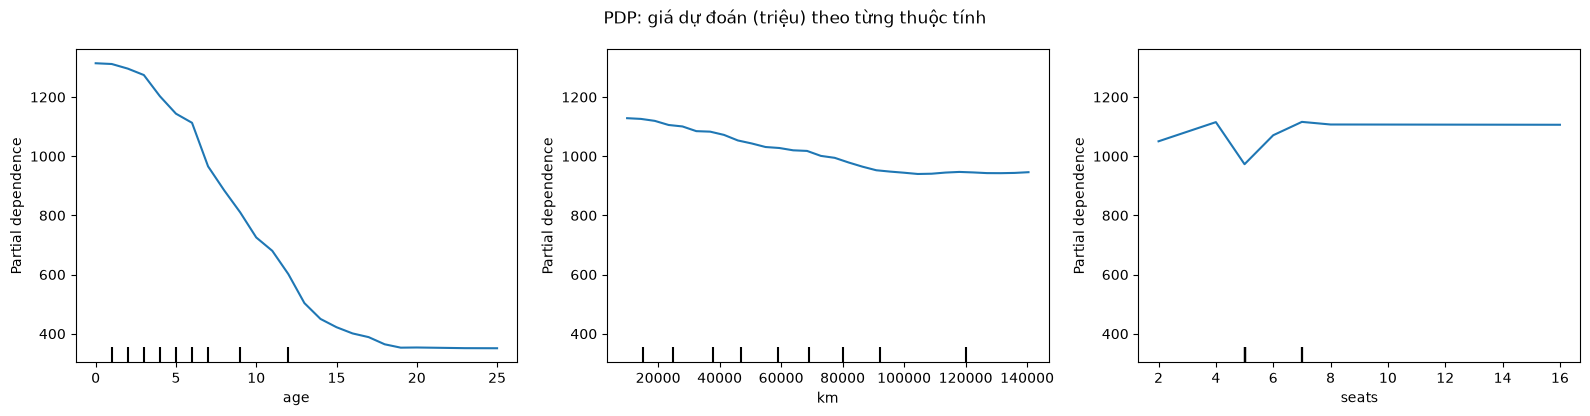

In [6]:
X_pdp = X_te.astype({"age": float, "km": float, "seats": float})   # PDP không chấp nhận cột số nguyên
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
PartialDependenceDisplay.from_estimator(model, X_pdp, ["age", "km", "seats"], kind="average", ax=ax, grid_resolution=30)
plt.suptitle("PDP: giá dự đoán (triệu) theo từng thuộc tính"); plt.tight_layout(); plt.show()

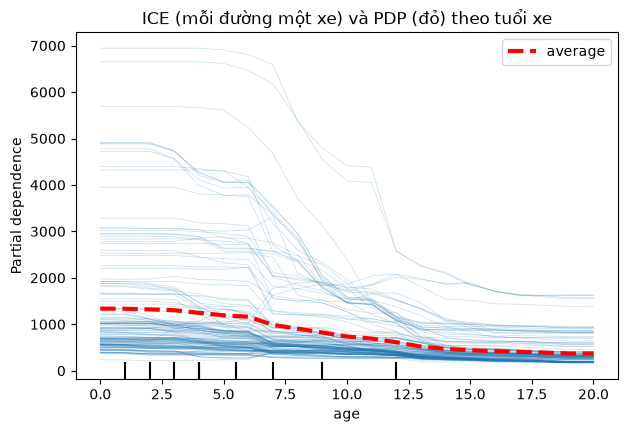

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
PartialDependenceDisplay.from_estimator(model, X_te.astype({"age": float, "km": float, "seats": float}).sample(150, random_state=0), ["age"], kind="both", ax=ax, ice_lines_kw={"alpha": .25}, pd_line_kw={"color": "r", "lw": 3})
ax.set_title("ICE (mỗi đường một xe) và PDP (đỏ) theo tuổi xe"); plt.show()

**Đọc ICE:** các đường **không song song**: xe đắt mất nhiều giá tuyệt đối hơn xe rẻ khi cũ đi. PDP (đường đỏ) che giấu sự khác biệt này. Nếu các đường cắt nhau hoặc phân nhóm rõ, có tương tác mạnh giữa thuộc tính này và thuộc tính khác (vd. hãng).

## 5. Phân tích what-if cho một chiếc xe cụ thể

Xe gốc: {'brand': 'Toyota', 'model': 'Fortuner', 'gearbox': 'tự động', 'fuel': 'dầu', 'province': 'Hà Nội', 'origin': 'trong nước', 'age': 5, 'km': 60000, 'seats': 7}
Giá dự đoán: 817 triệu



,thay đổi,giá dự đoán,chênh lệch
0,tuổi 3 thay vì 5,918,+12.4%
1,tuổi 8 thay vì 5,585,-28.3%
2,km 30.000,889,+8.8%
3,km 120.000,770,-5.7%
4,hộp số sàn,655,-19.9%
5,chạy xăng,635,-22.3%
6,bán ở TP HCM,805,-1.5%


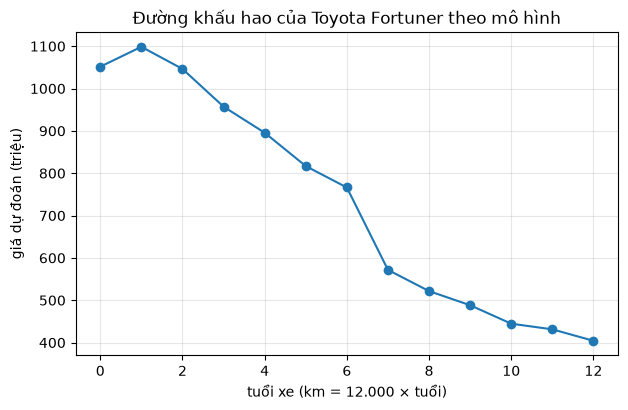

In [8]:
base_car = {"brand": "Toyota", "model": "Fortuner", "gearbox": "tự động", "fuel": "dầu", "province": "Hà Nội",
            "origin": "trong nước", "age": 5, "km": 60000, "seats": 7}
def price_of(**kw): return float(model.predict(pd.DataFrame([{**base_car, **kw}])[FEATURES])[0])
p0 = price_of(); print(f"Xe gốc: {base_car}\nGiá dự đoán: {p0:,.0f} triệu\n")

rows = []
for label, kw in [("tuổi 3 thay vì 5", {"age": 3}), ("tuổi 8 thay vì 5", {"age": 8}), ("km 30.000", {"km": 30000}), ("km 120.000", {"km": 120000}),
                  ("hộp số sàn", {"gearbox": "số sàn"}), ("chạy xăng", {"fuel": "xăng"}), ("bán ở TP HCM", {"province": "TP HCM"})]:
    p = price_of(**kw); rows.append({"thay đổi": label, "giá dự đoán": round(p), "chênh lệch": f"{(p / p0 - 1):+.1%}"})
display(pd.DataFrame(rows))

ages = np.arange(0, 13); plt.plot(ages, [price_of(age=a, km=a * 12000) for a in ages], "o-"); plt.xlabel("tuổi xe (km = 12.000 × tuổi)")
plt.ylabel("giá dự đoán (triệu)"); plt.title("Đường khấu hao của Toyota Fortuner theo mô hình"); plt.grid(alpha=.3); plt.show()

Đây là cách trả lời câu hỏi thực tế "xe này giảm bao nhiêu nếu đi thêm 30.000 km?". Hãy so sánh với hệ số tuyến tính ở notebook 02: hai mô hình có cùng kể một câu chuyện không?

## 6. Những điều không nên suy diễn

- **Quan trọng ≠ nhân quả.** Mô hình nói `brand` quan trọng, không có nghĩa đổi hãng sẽ đổi giá chiếc xe của bạn.
- **Tương quan giữa đặc trưng** làm chia sẻ và che lấp độ quan trọng (age và km).
- **PDP giả định các thuộc tính độc lập**: nó có thể xét những tổ hợp phi thực tế (xe mới 0 tuổi mà đi 200.000 km).
- Giải thích chỉ **mô tả mô hình**, không phải thế giới thực. Mô hình có thể học lỗi hoặc thiên lệch của dữ liệu (vd. giá chào bán).

## Bài tập
1. Vẽ PDP 2 chiều cho `age` và `km` (`features=[("age", "km")]`). Nhận xét.
2. Tính permutation importance trên tập **train** và so với tập test. Chênh lệch nói lên điều gì?
3. Xây what-if cho một Mercedes C300 và một Kia Morning. Đường khấu hao có dạng khác nhau không?
4. Cài `shap` (`pip install shap`) và vẽ `summary_plot` cho mô hình này; so với permutation importance.
5. Nhóm các giá trị hiếm của `model` thành "Khác" rồi so sánh lại độ quan trọng của `model`.